In [1]:
import sys
sys.path.append("../src")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL

from series import load_monthly_revenue

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

In [6]:
y = load_monthly_revenue()

print("Months:", len(y), "| from", y.index.min().date(), "to", y.index.max().date())
print("Missing values:", int(y.isna().sum()), "| frequency:", y.index.freqstr)
print("Total revenue:", round(y.sum(), 2))
print("Last 12 months:", round(y.tail(12).sum(), 0))
print("First value:", round(y.iloc[0], 0), "| Dec 2019:", round(y["2019-12-01"], 0))
assert len(y) == 61 and y.isna().sum() == 0

Months: 61 | from 2016-01-01 to 2021-01-01
Missing values: 0 | frequency: MS
Total revenue: 55229212.69
Last 12 months: 7738703.0
First value: 649919.0 | Dec 2019: 2477296.0


In [3]:
# If seasonal swings grow with the level of the business, a log transform is justified.
rows = []
for yr in range(2016, 2021):
    sub = y[str(yr)]
    mean_m = sub.mean()
    dec = y[f"{yr}-12-01"]
    rows.append({"year": yr, "avg_month": mean_m, "december": dec,
                 "dec_minus_avg": dec - mean_m, "dec_over_avg": dec / mean_m})
print(pd.DataFrame(rows).round(2).to_string(index=False))

 year    avg_month     december  dec_minus_avg  dec_over_avg
 2016   578,899.46   998,403.46     419,504.00          1.72
 2017   618,451.86 1,287,177.07     668,725.21          2.08
 2018 1,065,746.72 2,082,206.04   1,016,459.32          1.95
 2019 1,522,031.87 2,477,295.85     955,263.98          1.63
 2020   774,552.68   651,526.44    -123,026.24          0.84


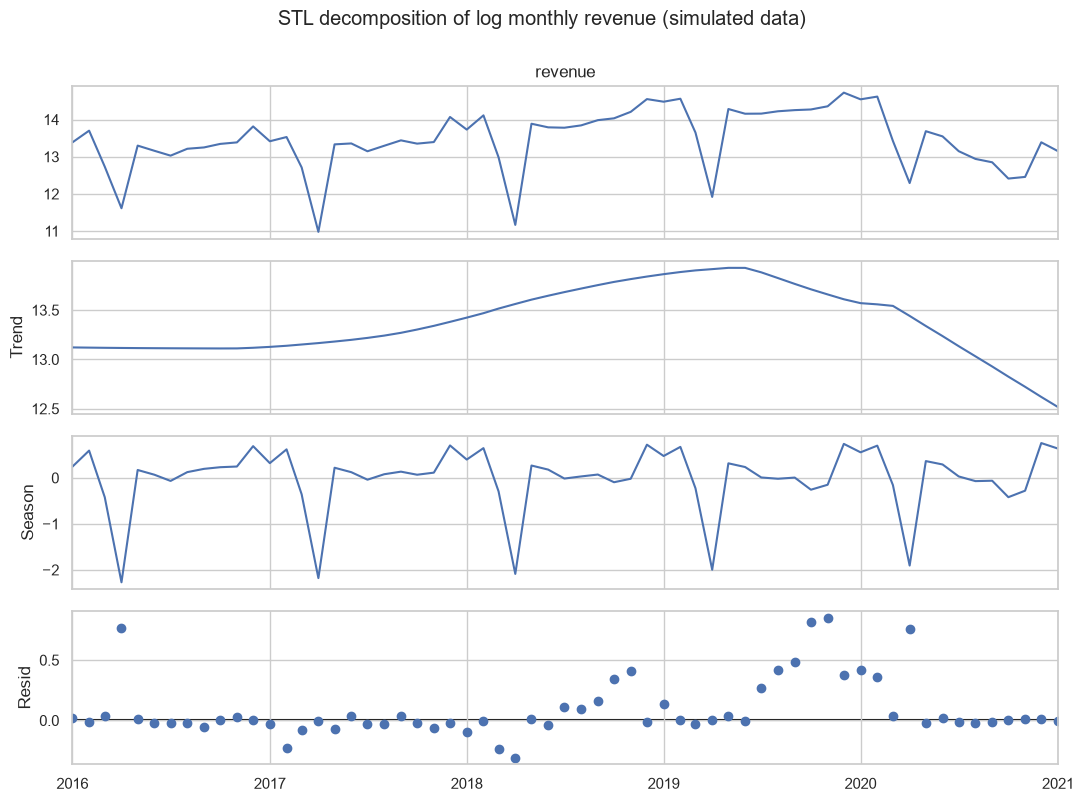

      mean    min    max
Jan 156.00 127.00 189.00
Feb 191.00 181.00 201.00
Mar  75.00  66.00  85.00
Apr  12.00  10.00  15.00
May 131.00 119.00 144.00
Jun 120.00 107.00 134.00
Jul  98.00  94.00 103.00
Aug 103.00  93.00 113.00
Sep 108.00  94.00 122.00
Oct  93.00  66.00 126.00
Nov 100.00  76.00 128.00
Dec 206.00 199.00 213.00

Residual std (log scale): 0.244 | log-series std: 0.797
Residuals beyond 2 std: ['2016-04', '2019-10', '2019-11', '2020-04']
Mean residual by year:
month
2016    0.06
2017   -0.04
2018    0.04
2019    0.28
2020    0.13
2021   -0.00


In [5]:
ly = np.log(y)
stl = STL(ly, period=12, seasonal=13, robust=True).fit()

fig = stl.plot()
fig.set_size_inches(11, 8)
fig.suptitle("STL decomposition of log monthly revenue (simulated data)", y=1.0)
plt.tight_layout()
plt.savefig("../reports/figures/stl_decomposition.png", dpi=150)
plt.show()

# Seasonal factors as percentages of an average month. The column is NOT called "month":
# the series index already has that name, which caused the ambiguity error.
sf = np.exp(stl.seasonal).rename("factor").to_frame()
sf["cal_month"] = sf.index.month
tab = sf.groupby("cal_month")["factor"].agg(["mean", "min", "max"]).mul(100).round(0)
tab.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
print(tab.to_string())

resid = stl.resid
print("\nResidual std (log scale):", round(resid.std(), 3), "| log-series std:", round(ly.std(), 3))
print("Residuals beyond 2 std:", [d.strftime("%Y-%m") for d in resid.index[abs(resid) > 2 * resid.std()]])
print("Mean residual by year:")
print(resid.groupby(resid.index.year).mean().round(2).to_string())

In [7]:
from backtest import rolling_origin, add_regime, summarise, leakage_check

def seasonal_naive(train, h):
    """Forecast each future month as the same month one year earlier."""
    n = len(train)
    return np.array([train.iloc[n - 12 + k] for k in range(h)])

bt_naive = add_regime(rolling_origin(y, seasonal_naive))

print("Origins:", bt_naive["origin"].nunique(), "| forecasts:", len(bt_naive))
print(bt_naive.groupby("regime")["origin"].nunique().to_string())
print("First origin:", bt_naive["origin"].min().date(), "| last origin:", bt_naive["origin"].max().date())
print("First target:", bt_naive["target"].min().date(), "| last target:", bt_naive["target"].max().date())

ok, n_rows = leakage_check(y, seasonal_naive)
print("Leakage check passed:", ok, "| forecasts compared:", n_rows)

first = bt_naive.iloc[0]
print(f"\nHand check: forecast for {first['target'].date()} = {first['forecast']:,.0f} "
      f"| Jan 2018 actual = {y['2018-01-01']:,.0f} | actual Jan 2019 = {first['actual']:,.0f}")

Origins: 23 | forecasts: 69
regime
pre-break             12
touches 2020 break    11
First origin: 2018-12-01 | last origin: 2020-10-01
First target: 2019-01-01 | last target: 2021-01-01
Leakage check passed: True | forecasts compared: 42

Hand check: forecast for 2019-01-01 = 917,075 | Jan 2018 actual = 917,075 | actual Jan 2019 = 1,940,900


In [8]:
res = summarise(bt_naive)
res.round(1)

n          MAE         RMSE  MAPE_%  \
pre-break          all months    36.00   388,908.80   434,126.00   29.20   
                   excl. Mar/Apr 30.00   417,666.70   456,771.50   24.90   
touches 2020 break all months    33.00   853,960.60 1,010,854.40  215.20   
                   excl. Mar/Apr 27.00 1,017,209.20 1,115,859.60  256.70   
all origins        all months    69.00   611,324.90   766,178.50  118.10   
                   excl. Mar/Apr 57.00   701,660.50   836,430.00  134.70   

                                  WAPE_%  bias_%  
pre-break          all months      25.40  -25.40  
                   excl. Mar/Apr   24.00  -24.00  
touches 2020 break all months     131.80  126.40  
                   excl. Mar/Apr  146.90  142.80  
all origins        all months      55.10   17.00  
                   excl. Mar/Apr   56.40   20.00

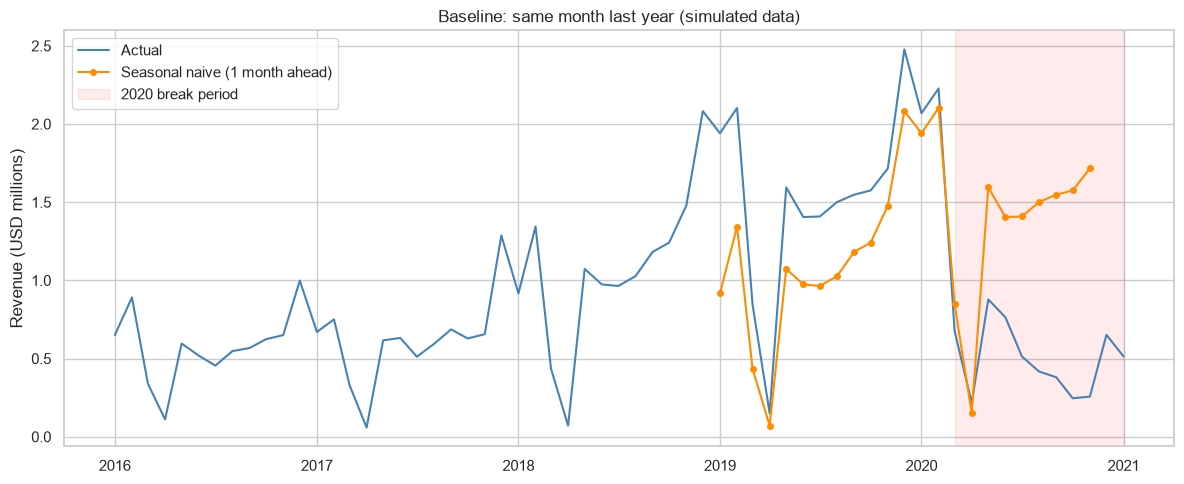

,origin,h,target,actual,forecast,abs_err
65,2020-09-01,3,2020-12-01,"651,526.00","2,477,296.00","1,825,769.00"
67,2020-10-01,2,2020-12-01,"651,526.00","2,477,296.00","1,825,769.00"
68,2020-10-01,3,2021-01-01,"513,022.00","2,068,951.00","1,555,930.00"
62,2020-08-01,3,2020-11-01,"256,701.00","1,715,660.00","1,458,959.00"
64,2020-09-01,2,2020-11-01,"256,701.00","1,715,660.00","1,458,959.00"
66,2020-10-01,1,2020-11-01,"256,701.00","1,715,660.00","1,458,959.00"
59,2020-07-01,3,2020-10-01,"245,648.00","1,575,169.00","1,329,521.00"
61,2020-08-01,2,2020-10-01,"245,648.00","1,575,169.00","1,329,521.00"


In [9]:
h1 = bt_naive[bt_naive["h"] == 1].set_index("target")
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y.index, y / 1e6, color="steelblue", label="Actual")
ax.plot(h1.index, h1["forecast"] / 1e6, color="darkorange", marker="o", markersize=4,
        label="Seasonal naive (1 month ahead)")
ax.axvspan(pd.Timestamp("2020-03-01"), y.index[-1], color="red", alpha=0.08, label="2020 break period")
ax.set_title("Baseline: same month last year (simulated data)")
ax.set_ylabel("Revenue (USD millions)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/baseline_forecast.png", dpi=150)
plt.show()

bt_naive["abs_err"] = (bt_naive["forecast"] - bt_naive["actual"]).abs()
bt_naive.nlargest(8, "abs_err")[["origin", "h", "target", "actual", "forecast", "abs_err"]] \
        .round({"actual": 0, "forecast": 0, "abs_err": 0})

In [10]:
import forecasters as fcs
from backtest import rolling_origin, add_regime, summarise, leakage_check, metrics

ok, n_rows = leakage_check(y, fcs.ets_log)
print("ETS leakage check passed:", ok, "| forecasts compared:", n_rows)

fcs.LOG.clear()                                   # the leakage check also logged calls; start clean
bt_ets = add_regime(rolling_origin(y, fcs.ets_log))
ets_log = pd.DataFrame(fcs.LOG)

assert len(bt_ets) == 69 and np.isfinite(bt_ets["forecast"]).all() and (bt_ets["forecast"] > 0).all()
print("Origins:", bt_ets["origin"].nunique(), "| forecasts:", len(bt_ets))
print(ets_log["status"].value_counts().to_string())
print("Origins with any warning:", int((ets_log["n_warnings"] > 0).sum()))
print("Damping factor phi: min", ets_log["phi"].min(), "| median", ets_log["phi"].median(), "| max", ets_log["phi"].max())
summarise(bt_ets).round(1)

ETS leakage check passed: True | forecasts compared: 42
Origins: 23 | forecasts: 69
status
ok    23
Origins with any warning: 0
Damping factor phi: min 0.919 | median 0.956 | max 0.995


n        MAE       RMSE  MAPE_%  WAPE_%  \
pre-break          all months    36.00 157,999.30 194,006.60   12.00   10.30   
                   excl. Mar/Apr 30.00 178,713.20 210,969.90   10.30   10.30   
touches 2020 break all months    33.00 325,628.50 417,170.40   58.70   50.30   
                   excl. Mar/Apr 27.00 369,602.70 455,614.20   65.90   53.40   
all origins        all months    69.00 238,169.80 320,733.20   34.30   21.50   
                   excl. Mar/Apr 57.00 269,134.60 348,933.90   36.70   21.60   

                                  bias_%  
pre-break          all months       8.10  
                   excl. Mar/Apr    8.00  
touches 2020 break all months      36.60  
                   excl. Mar/Apr   39.20  
all origins        all months      16.10  
                   excl. Mar/Apr   16.20

In [11]:
ok, n_rows = leakage_check(y, fcs.sarima_log)
print("SARIMA leakage check passed:", ok, "| forecasts compared:", n_rows)

fcs.LOG.clear()
bt_sar = add_regime(rolling_origin(y, fcs.sarima_log))
sar_log = pd.DataFrame(fcs.LOG)

assert len(bt_sar) == 69 and np.isfinite(bt_sar["forecast"]).all() and (bt_sar["forecast"] > 0).all()
print(sar_log["status"].value_counts().to_string())
print("Converged fits per origin (of 12): min", sar_log["n_converged"].min(),
      "| median", sar_log["n_converged"].median())
print("\nOrder chosen, by how often:")
print(sar_log["order"].value_counts().to_string())
summarise(bt_sar).round(1)

SARIMA leakage check passed: True | forecasts compared: 42
status
ok    23
Converged fits per origin (of 12): min 8 | median 11.0

Order chosen, by how often:
order
(1, 1, 0)x(1, 1, 0, 12)    9
(0, 1, 1)x(1, 1, 0, 12)    8
(0, 1, 1)x(0, 1, 1, 12)    4
(1, 1, 1)x(1, 1, 0, 12)    2


n        MAE       RMSE  MAPE_%  WAPE_%  \
pre-break          all months    36.00 303,693.30 355,373.70   19.30   19.80   
                   excl. Mar/Apr 30.00 358,739.30 389,058.80   20.80   20.60   
touches 2020 break all months    33.00 373,096.20 484,065.30   71.30   57.60   
                   excl. Mar/Apr 27.00 416,926.30 525,817.70   79.10   60.20   
all origins        all months    69.00 336,886.00 421,848.80   44.20   30.40   
                   excl. Mar/Apr 57.00 386,301.60 458,947.60   48.40   31.10   

                                  bias_%  
pre-break          all months      18.50  
                   excl. Mar/Apr   19.90  
touches 2020 break all months      51.90  
                   excl. Mar/Apr   55.70  
all origins        all months      27.90  
                   excl. Mar/Apr   29.30

In [12]:
models = {"Seasonal naive": bt_naive, "ETS": bt_ets, "SARIMA": bt_sar}

rows = []
for name, b in models.items():
    for reg in ["pre-break", "touches 2020 break"]:
        m = metrics(b[b["regime"] == reg])
        rows.append({"model": name, "regime": reg, "WAPE_%": m["WAPE_%"], "bias_%": m["bias_%"], "MAE": m["MAE"]})
print(pd.DataFrame(rows).round(1).to_string(index=False))

print("\nWAPE % by horizon (months ahead):")
rows = []
for name, b in models.items():
    for reg in ["pre-break", "touches 2020 break"]:
        g = b[b["regime"] == reg]
        rows.append({"model": name, "regime": reg,
                     **{f"h={k}": metrics(g[g["h"] == k])["WAPE_%"] for k in (1, 2, 3)}})
print(pd.DataFrame(rows).round(1).to_string(index=False))

print("\nOrigins where the model's total absolute error beats seasonal naive:")
err = {n: b.assign(ae=(b["forecast"] - b["actual"]).abs()).groupby(["origin", "regime"])["ae"].sum()
       for n, b in models.items()}
for n in ("ETS", "SARIMA"):
    win = (err[n] < err["Seasonal naive"]).groupby("regime").agg(["sum", "count"])
    print(n, win.rename(columns={"sum": "wins", "count": "origins"}).to_dict("index"))

         model             regime  WAPE_%  bias_%        MAE
Seasonal naive          pre-break   25.40  -25.40 388,908.80
Seasonal naive touches 2020 break  131.80  126.40 853,960.60
           ETS          pre-break   10.30    8.10 157,999.30
           ETS touches 2020 break   50.30   36.60 325,628.50
        SARIMA          pre-break   19.80   18.50 303,693.30
        SARIMA touches 2020 break   57.60   51.90 373,096.20

WAPE % by horizon (months ahead):
         model             regime   h=1    h=2    h=3
Seasonal naive          pre-break 30.00  24.90  21.30
Seasonal naive touches 2020 break 90.10 131.20 198.00
           ETS          pre-break  9.30   9.30  12.20
           ETS touches 2020 break 29.80  47.80  85.50
        SARIMA          pre-break 16.30  20.30  22.80
        SARIMA touches 2020 break 38.30  50.30  97.30

Origins where the model's total absolute error beats seasonal naive:
ETS {'pre-break': {'wins': 12, 'origins': 12}, 'touches 2020 break': {'wins': 7, 'origins'

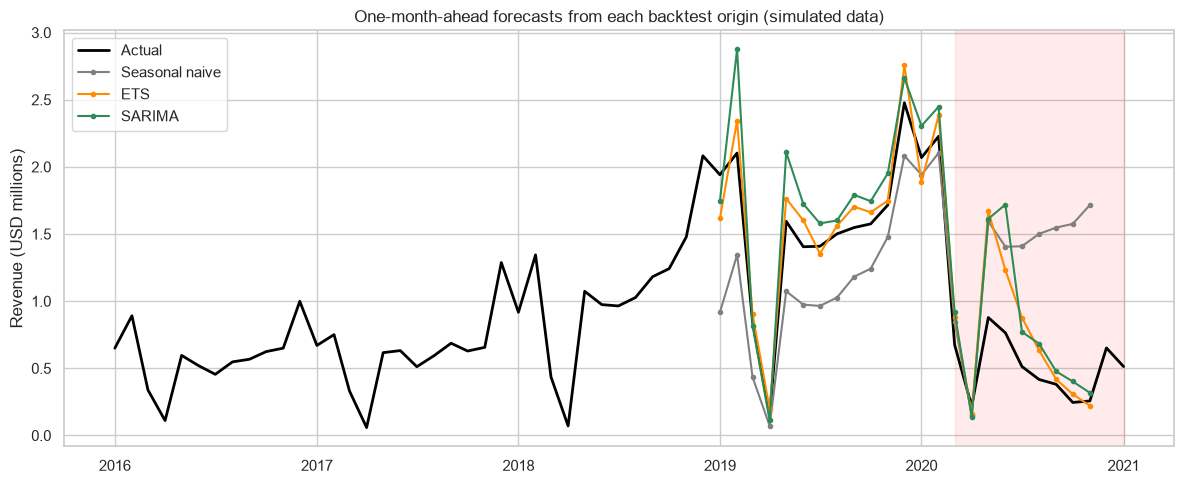

In [13]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y.index, y / 1e6, color="black", linewidth=2, label="Actual")
colours = {"Seasonal naive": "grey", "ETS": "darkorange", "SARIMA": "seagreen"}
for name, b in models.items():
    h1 = b[b["h"] == 1].set_index("target")
    ax.plot(h1.index, h1["forecast"] / 1e6, marker="o", markersize=3, color=colours[name], label=name)
ax.axvspan(pd.Timestamp("2020-03-01"), y.index[-1], color="red", alpha=0.08)
ax.set_title("One-month-ahead forecasts from each backtest origin (simulated data)")
ax.set_ylabel("Revenue (USD millions)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/model_comparison.png", dpi=150)
plt.show()

In [14]:
# Per-origin total absolute error (USD thousands) for each model
err = {n: b.assign(ae=(b["forecast"] - b["actual"]).abs()).groupby(["origin", "regime"])["ae"].sum()
       for n, b in models.items()}
cmp = pd.DataFrame(err) / 1e3
cmp["ETS<naive"] = cmp["ETS"] < cmp["Seasonal naive"]
cmp["ETS<SARIMA"] = cmp["ETS"] < cmp["SARIMA"]
print(cmp.round(0).to_string())
print("\nWins by regime:")
print(cmp.groupby(level="regime")[["ETS<naive", "ETS<SARIMA"]].agg(["sum", "count"]).to_string())

# H: models over-forecast 2019 because they extrapolate 2018's faster growth.
h1 = bt_ets[bt_ets["h"] == 1].set_index("target")
prev = y.shift(12).reindex(h1.index)
g = pd.DataFrame({"actual_yoy_%": 100 * (h1["actual"] / prev - 1),
                  "ets_implied_yoy_%": 100 * (h1["forecast"] / prev - 1)})
g19 = g[g.index.year == 2019]
print("\n2019 YoY growth, actual vs ETS 1-month-ahead forecast (all months):")
print(g19.round(0).to_string())
ex = g19[~g19.index.month.isin([3, 4])]
print("Mean excluding Mar/Apr -> actual:", round(ex["actual_yoy_%"].mean(), 0),
      "| ETS:", round(ex["ets_implied_yoy_%"].mean(), 0))


                               Seasonal naive      ETS   SARIMA  ETS<naive  ETS<SARIMA
origin     regime                                                                     
2018-12-01 pre-break                 2,193.00   464.00   873.00       True        True
2019-01-01 pre-break                 1,249.00   387.00   802.00       True        True
2019-02-01 pre-break                 1,011.00   488.00   488.00       True       False
2019-03-01 pre-break                 1,031.00   841.00   788.00       True       False
2019-04-01 pre-break                 1,397.00   537.00 1,502.00       True        True
2019-05-01 pre-break                 1,349.00   362.00   917.00       True        True
2019-06-01 pre-break                 1,285.00   237.00   749.00       True        True
2019-07-01 pre-break                 1,173.00   417.00   738.00       True        True
2019-08-01 pre-break                   937.00   440.00 1,012.00       True        True
2019-09-01 pre-break                   966.

In [2]:
import importlib
importlib.reload(fcs)

for f, name in [(fcs.ridge_log, "Ridge"), (fcs.ridge_break_log, "Ridge+break")]:
    ok, n_rows = leakage_check(y, f)
    print(name, "leakage check passed:", ok, "| forecasts compared:", n_rows)

fcs.LOG.clear()
bt_rdg = add_regime(rolling_origin(y, fcs.ridge_log))
rdg_log = pd.DataFrame(fcs.LOG)

fcs.LOG.clear()
bt_rbk = add_regime(rolling_origin(y, fcs.ridge_break_log))
rbk_log = pd.DataFrame(fcs.LOG)

for b in (bt_rdg, bt_rbk):
    assert len(b) == 69 and np.isfinite(b["forecast"]).all() and (b["forecast"] > 0).all()

print("\nStatus:", rdg_log["status"].value_counts().to_dict(), rbk_log["status"].value_counts().to_dict())
print("Fitted annual growth (%), by origin: first", rdg_log["annual_growth_pct"].iloc[0],
      "| median", rdg_log["annual_growth_pct"].median(), "| last", rdg_log["annual_growth_pct"].iloc[-1])

same = bt_rdg["origin"] < "2020-03-01"
print("\nRidge and Ridge+break identical before the break is visible (45 forecasts):",
      same.sum(), np.allclose(bt_rdg.loc[same, "forecast"].values, bt_rbk.loc[same, "forecast"].values))
print(rbk_log.loc[rbk_log["n_post_break_train"] > 0, ["origin", "n_post_break_train", "post_break_coef"]]
      .assign(origin=lambda d: d["origin"].dt.strftime("%Y-%m")).to_string(index=False))

summarise(bt_rdg).round(1)

NameError: name 'fcs' is not defined

In [3]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from series import load_monthly_revenue
from backtest import rolling_origin, add_regime, summarise, leakage_check, metrics
import forecasters as fcs

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

y = load_monthly_revenue()
assert len(y) == 61 and y.isna().sum() == 0

fcs.LOG.clear()
bt_naive = add_regime(rolling_origin(y, fcs.seasonal_naive))
bt_ets = add_regime(rolling_origin(y, fcs.ets_log))
bt_sar = add_regime(rolling_origin(y, fcs.sarima_log))      # the slow one: expect a few minutes

# Reproducibility check against the reconciled Module 5.3/5.4 results
expected = {"naive": (bt_naive, 25.4, 131.8), "ETS": (bt_ets, 10.3, 50.3), "SARIMA": (bt_sar, 19.8, 57.6)}
for name, (b, pre, brk) in expected.items():
    got_pre = metrics(b[b["regime"] == "pre-break"])["WAPE_%"]
    got_brk = metrics(b[b["regime"] != "pre-break"])["WAPE_%"]
    print(f"{name:7s} pre-break WAPE {got_pre:5.1f} (expected {pre}) | break WAPE {got_brk:5.1f} (expected {brk})")
    assert abs(got_pre - pre) < 0.1 and abs(got_brk - brk) < 0.1, f"{name} does not reproduce"

print("hasattr ridge_log:", hasattr(fcs, "ridge_log"), "| ridge_break_log:", hasattr(fcs, "ridge_break_log"))

naive   pre-break WAPE  25.4 (expected 25.4) | break WAPE 131.8 (expected 131.8)
ETS     pre-break WAPE  10.3 (expected 10.3) | break WAPE  50.3 (expected 50.3)
SARIMA  pre-break WAPE  19.8 (expected 19.8) | break WAPE  57.6 (expected 57.6)
hasattr ridge_log: True | ridge_break_log: True


In [4]:
import importlib
importlib.reload(fcs)

for f, name in [(fcs.ridge_log, "Ridge"), (fcs.ridge_break_log, "Ridge+break")]:
    ok, n_rows = leakage_check(y, f)
    print(name, "leakage check passed:", ok, "| forecasts compared:", n_rows)

fcs.LOG.clear()
bt_rdg = add_regime(rolling_origin(y, fcs.ridge_log))
rdg_log = pd.DataFrame(fcs.LOG)

fcs.LOG.clear()
bt_rbk = add_regime(rolling_origin(y, fcs.ridge_break_log))
rbk_log = pd.DataFrame(fcs.LOG)

for b in (bt_rdg, bt_rbk):
    assert len(b) == 69 and np.isfinite(b["forecast"]).all() and (b["forecast"] > 0).all()

print("\nStatus:", rdg_log["status"].value_counts().to_dict(), rbk_log["status"].value_counts().to_dict())
print("Fitted annual growth (%), by origin: first", rdg_log["annual_growth_pct"].iloc[0],
      "| median", rdg_log["annual_growth_pct"].median(), "| last", rdg_log["annual_growth_pct"].iloc[-1])

same = bt_rdg["origin"] < "2020-03-01"
print("\nRidge and Ridge+break identical before the break is visible (45 forecasts):",
      same.sum(), np.allclose(bt_rdg.loc[same, "forecast"].values, bt_rbk.loc[same, "forecast"].values))
print(rbk_log.loc[rbk_log["n_post_break_train"] > 0, ["origin", "n_post_break_train", "post_break_coef"]]
      .assign(origin=lambda d: d["origin"].dt.strftime("%Y-%m")).to_string(index=False))

summarise(bt_rdg).round(1)

Ridge leakage check passed: True | forecasts compared: 42
Ridge+break leakage check passed: True | forecasts compared: 42

Status: {'fallback: NameError': 23} {'fallback: NameError': 23}


KeyError: 'annual_growth_pct'

In [5]:
import importlib
import forecasters as fcs
importlib.reload(fcs)

# 1. Leakage checks (42 forecasts each)
for f, name in [(fcs.ridge_log, "Ridge"), (fcs.ridge_break_log, "Ridge+break")]:
    ok, n_rows = leakage_check(y, f)
    print(name, "leakage check passed:", ok, "| forecasts compared:", n_rows)

# 2. Backtests
fcs.LOG.clear()
bt_rdg = add_regime(rolling_origin(y, fcs.ridge_log))
rdg_log = pd.DataFrame(fcs.LOG)

fcs.LOG.clear()
bt_rbk = add_regime(rolling_origin(y, fcs.ridge_break_log))
rbk_log = pd.DataFrame(fcs.LOG)

# 3. Guard: no silent fallbacks, and a clear message if one happens
for name, lg in [("Ridge", rdg_log), ("Ridge+break", rbk_log)]:
    bad = lg[lg["status"] != "ok"]
    assert bad.empty, f"{name}: {len(bad)} origins fell back. First status: {bad['status'].iloc[0]}"

for b in (bt_rdg, bt_rbk):
    assert len(b) == 69 and np.isfinite(b["forecast"]).all() and (b["forecast"] > 0).all()

print("\nStatus:", rdg_log["status"].value_counts().to_dict(), rbk_log["status"].value_counts().to_dict())
print("Fitted annual growth (%): first", rdg_log["annual_growth_pct"].iloc[0],
      "| median", rdg_log["annual_growth_pct"].median(),
      "| last", rdg_log["annual_growth_pct"].iloc[-1])

# 4. Before the break is visible, the flag has nothing to learn from: forecasts must be identical
same = bt_rdg["origin"] < "2020-03-01"
print("\nIdentical before the break:", int(same.sum()), "forecasts,",
      np.allclose(bt_rdg.loc[same, "forecast"].values, bt_rbk.loc[same, "forecast"].values))
print(rbk_log.loc[rbk_log["n_post_break_train"] > 0, ["origin", "n_post_break_train", "post_break_coef"]]
      .assign(origin=lambda d: d["origin"].dt.strftime("%Y-%m")).to_string(index=False))

summarise(bt_rdg).round(1)

Ridge leakage check passed: True | forecasts compared: 42
Ridge+break leakage check passed: True | forecasts compared: 42

Status: {'ok': 23} {'ok': 23}
Fitted annual growth (%): first 28.8 | median 36.3 | last 17.9

Identical before the break: 45 forecasts, True
 origin  n_post_break_train  post_break_coef
2020-03                   1            -0.37
2020-04                   2            -0.19
2020-05                   3            -0.39
2020-06                   4            -0.51
2020-07                   5            -0.64
2020-08                   6            -0.78
2020-09                   7            -0.91
2020-10                   8            -1.06


n          MAE         RMSE  MAPE_%  \
pre-break          all months    36.00   185,083.60   242,935.40   11.70   
                   excl. Mar/Apr 30.00   202,339.30   258,744.10   11.60   
touches 2020 break all months    33.00   989,094.80 1,117,192.30  234.30   
                   excl. Mar/Apr 27.00 1,168,611.60 1,229,286.80  280.30   
all origins        all months    69.00   569,610.70   792,286.60  118.20   
                   excl. Mar/Apr 57.00   660,047.30   866,626.80  138.90   

                                  WAPE_%  bias_%  
pre-break          all months      12.10   -8.80  
                   excl. Mar/Apr   11.60   -8.20  
touches 2020 break all months     152.70  151.40  
                   excl. Mar/Apr  168.70  167.30  
all origins        all months      51.30   35.90  
                   excl. Mar/Apr   53.10   38.10

In [6]:
models = {"Seasonal naive": bt_naive, "ETS": bt_ets, "SARIMA": bt_sar,
          "Ridge": bt_rdg, "Ridge+break": bt_rbk}

rows = []
for name, b in models.items():
    for reg in ["pre-break", "touches 2020 break"]:
        m = metrics(b[b["regime"] == reg])
        rows.append({"model": name, "regime": reg, "WAPE_%": m["WAPE_%"], "bias_%": m["bias_%"]})
print(pd.DataFrame(rows).round(1).to_string(index=False))

print("\nOrigins March to October 2020 only (break visible in training):")
for name, b in models.items():
    m = metrics(b[b["origin"] >= "2020-03-01"])
    print(f"  {name:15s} n={int(m['n'])}  WAPE={m['WAPE_%']:.1f}%  bias={m['bias_%']:+.1f}%")

err = {n: b.assign(ae=(b["forecast"] - b["actual"]).abs()).groupby(["origin", "regime"])["ae"].sum()
       for n, b in models.items()}
w = (err["Ridge"] < err["ETS"]).groupby("regime").agg(["sum", "count"])
print("\nOrigins where Ridge beats ETS:", w.rename(columns={"sum": "wins", "count": "origins"}).to_dict("index"))


         model             regime  WAPE_%  bias_%
Seasonal naive          pre-break   25.40  -25.40
Seasonal naive touches 2020 break  131.80  126.40
           ETS          pre-break   10.30    8.10
           ETS touches 2020 break   50.30   36.60
        SARIMA          pre-break   19.80   18.50
        SARIMA touches 2020 break   57.60   51.90
         Ridge          pre-break   12.10   -8.80
         Ridge touches 2020 break  152.70  151.40
   Ridge+break          pre-break   12.10   -8.80
   Ridge+break touches 2020 break   86.10   84.20

Origins March to October 2020 only (break visible in training):
  Seasonal naive  n=24  WAPE=229.5%  bias=+228.4%
  ETS             n=24  WAPE=76.6%  bias=+55.8%
  SARIMA          n=24  WAPE=83.6%  bias=+74.9%
  Ridge           n=24  WAPE=256.1%  bias=+255.9%
  Ridge+break     n=24  WAPE=132.5%  bias=+131.3%

Origins where Ridge beats ETS: {'pre-break': {'wins': 6, 'origins': 12}, 'touches 2020 break': {'wins': 0, 'origins': 11}}


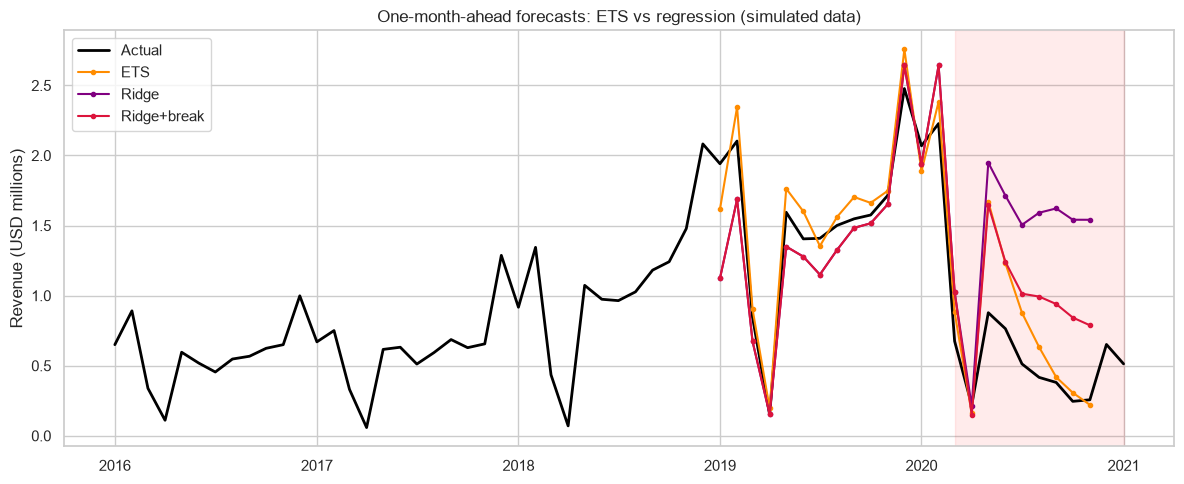

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y.index, y / 1e6, color="black", linewidth=2, label="Actual")
for name, col in [("ETS", "darkorange"), ("Ridge", "purple"), ("Ridge+break", "crimson")]:
    h1 = models[name][models[name]["h"] == 1].set_index("target")
    ax.plot(h1.index, h1["forecast"] / 1e6, marker="o", markersize=3, color=col, label=name)
ax.axvspan(pd.Timestamp("2020-03-01"), y.index[-1], color="red", alpha=0.08)
ax.set_title("One-month-ahead forecasts: ETS vs regression (simulated data)")
ax.set_ylabel("Revenue (USD millions)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/ridge_comparison.png", dpi=150)
plt.show()

In [8]:
def combine(a, b):
    k = ["origin", "target", "h"]
    m = a[k + ["forecast", "actual", "regime"]].merge(b[k + ["forecast"]], on=k, suffixes=("_a", "_b"))
    out = m[k + ["actual", "regime"]].copy()
    out["forecast"] = 0.5 * m["forecast_a"] + 0.5 * m["forecast_b"]
    return out

ens = {"ETS": bt_ets,
       "ETS+Ridge": combine(bt_ets, bt_rdg),
       "ETS+SARIMA": combine(bt_ets, bt_sar)}
assert all(len(v) == 69 for v in ens.values()), "row counts changed in the merge"

rows = []
for name, b in ens.items():
    for reg in ["pre-break", "touches 2020 break"]:
        m = metrics(b[b["regime"] == reg])
        rows.append({"model": name, "regime": reg, "WAPE_%": m["WAPE_%"], "bias_%": m["bias_%"]})
print(pd.DataFrame(rows).round(1).to_string(index=False))

print("\nOrigins March to October 2020 only:")
for name, b in ens.items():
    m = metrics(b[b["origin"] >= "2020-03-01"])
    print(f"  {name:12s} n={int(m['n'])}  WAPE={m['WAPE_%']:.1f}%  bias={m['bias_%']:+.1f}%")

     model             regime  WAPE_%  bias_%
       ETS          pre-break   10.30    8.10
       ETS touches 2020 break   50.30   36.60
 ETS+Ridge          pre-break    6.50   -0.30
 ETS+Ridge touches 2020 break   96.10   94.00
ETS+SARIMA          pre-break   14.30   13.30
ETS+SARIMA touches 2020 break   52.90   44.30

Origins March to October 2020 only:
  ETS          n=24  WAPE=76.6%  bias=+55.8%
  ETS+Ridge    n=24  WAPE=156.4%  bias=+155.9%
  ETS+SARIMA   n=24  WAPE=79.8%  bias=+65.4%


In [9]:
import numpy as np

e = bt_ets.assign(le=np.log(bt_ets["actual"] / bt_ets["forecast"]))
pre = e.loc[e["regime"] == "pre-break", "le"]
lo_q, hi_q = pre.quantile(0.10), pre.quantile(0.90)
print(f"Pre-break log errors: n={len(pre)}  q10={lo_q:.3f}  q90={hi_q:.3f}")
print(f"Band = forecast x {np.exp(lo_q):.2f} to forecast x {np.exp(hi_q):.2f}")

e["lo"] = e["forecast"] * np.exp(lo_q)
e["hi"] = e["forecast"] * np.exp(hi_q)
e["inside"] = (e["actual"] >= e["lo"]) & (e["actual"] <= e["hi"])

print("\nCoverage of the 80% band:")
print(e.groupby("regime")["inside"].agg(["mean", "sum", "count"]).round(2))
late = e[e["origin"] >= "2020-03-01"]["inside"]
print(f"\nMar-Oct 2020 origins: {int(late.sum())} of {len(late)} inside ({late.mean():.0%})")

Pre-break log errors: n=36  q10=-0.240  q90=0.011
Band = forecast x 0.79 to forecast x 1.01

Coverage of the 80% band:
                    mean  sum  count
regime                              
pre-break           0.78   28     36
touches 2020 break  0.18    6     33

Mar-Oct 2020 origins: 4 of 24 inside (17%)


In [10]:
s = bt_ets[(bt_ets["h"] == 1) & (bt_ets["target"] >= "2020-03-01")].copy()
s["err_%"] = (s["forecast"] / s["actual"] - 1) * 100
s["actual"] = (s["actual"] / 1e6).round(2)
s["forecast"] = (s["forecast"] / 1e6).round(2)
print(s[["target", "actual", "forecast", "err_%"]].round({"err_%": 0}).to_string(index=False))

    target  actual  forecast  err_%
2020-03-01    0.67      0.88  31.00
2020-04-01    0.22      0.16 -27.00
2020-05-01    0.88      1.67  90.00
2020-06-01    0.76      1.23  61.00
2020-07-01    0.51      0.88  71.00
2020-08-01    0.42      0.63  52.00
2020-09-01    0.38      0.42  10.00
2020-10-01    0.25      0.31  25.00
2020-11-01    0.26      0.22 -14.00


In [11]:
q10, q90 = e["le"].quantile(0.10), e["le"].quantile(0.90)
print(f"All 69 errors: q10={q10:.3f}  q90={q90:.3f}  -> band x{np.exp(q10):.2f} to x{np.exp(q90):.2f}")

e["inside_all"] = (e["actual"] >= e["forecast"] * np.exp(q10)) & (e["actual"] <= e["forecast"] * np.exp(q90))
print("\nCoverage with the all-errors band (in-sample, optimistic):")
print(e.groupby("regime")["inside_all"].agg(["mean", "sum", "count"]).round(2))

print("\nLog error by regime (negative = ETS over-forecast):")
print(e.groupby("regime")["le"].agg(["mean", "median", "std"]).round(3))

All 69 errors: q10=-0.652  q90=0.157  -> band x0.52 to x1.17

Coverage with the all-errors band (in-sample, optimistic):
                    mean  sum  count
regime                              
pre-break           0.97   35     36
touches 2020 break  0.61   20     33

Log error by regime (negative = ETS over-forecast):
                    mean  median  std
regime                               
pre-break          -0.09   -0.09 0.10
touches 2020 break -0.24   -0.29 0.53


In [13]:
import importlib, sys
try:
    fcs = importlib.reload(fcs)
except NameError:
    sys.path.append("../src")
    import forecasters as fcs
print("using:", fcs.__file__)

H_FINAL = 6
print("Series:", y.index[0].strftime("%Y-%m"), "to", y.index[-1].strftime("%Y-%m"), f"({len(y)} months)")

n_log = len(fcs.LOG)
idx = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=H_FINAL, freq="MS")
f_ets = pd.Series(np.asarray(fcs.ets_log(y, H_FINAL), dtype=float), index=idx)
f_rbk = pd.Series(np.asarray(fcs.ridge_break_log(y, H_FINAL), dtype=float), index=idx)
print("Fit log:", fcs.LOG[n_log:])
assert not any("fallback" in str(r) for r in fcs.LOG[n_log:]), "a model fell back - do not use these numbers"

e_le = np.log(bt_ets["actual"] / bt_ets["forecast"])
st_lo, st_hi = e_le[bt_ets["regime"] == "pre-break"].quantile([0.10, 0.90])
wd_lo, wd_hi = e_le.quantile([0.10, 0.90])
print(f"Stable band x{np.exp(st_lo):.2f} to x{np.exp(st_hi):.2f} | Regime-risk band x{np.exp(wd_lo):.2f} to x{np.exp(wd_hi):.2f}")

fc = pd.DataFrame({
    "forecast": f_ets,
    "stable_lo": f_ets * np.exp(st_lo), "stable_hi": f_ets * np.exp(st_hi),
    "wide_lo": f_ets * np.exp(wd_lo), "wide_hi": f_ets * np.exp(wd_hi),
    "ridge_break": f_rbk,
    "same_month_2020": y.loc["2020-02-01":"2020-07-01"].values,
})
out = (fc / 1e6).round(2)
out["vs_2020_%"] = ((fc["forecast"] / fc["same_month_2020"] - 1) * 100).round(0)
out.index = out.index.strftime("%Y-%m")
print(out.to_string())

print("\nLast 6 actual months ($M):")
print((y.tail(6) / 1e6).round(2).to_string())

using: c:\Users\rajam\Projects\sales-intelligence-system\notebooks\../src\forecasters.py
Series: 2016-01 to 2021-01 (61 months)
Fit log: [{'model': 'ETS', 'origin': Timestamp('2021-01-01 00:00:00'), 'status': 'ok', 'n_warnings': 0, 'phi': 0.995}, {'model': 'Ridge+break', 'origin': Timestamp('2021-01-01 00:00:00'), 'status': 'ok', 'annual_growth_pct': np.float64(37.1), 'n_post_break_train': 11, 'post_break_coef': -1.261}]
Stable band x0.79 to x1.01 | Regime-risk band x0.52 to x1.17
         forecast  stable_lo  stable_hi  wide_lo  wide_hi  ridge_break  same_month_2020  vs_2020_%
2021-02      0.61       0.48       0.62     0.32     0.72         0.97             2.23     -73.00
2021-03      0.23       0.18       0.23     0.12     0.26         0.46             0.67     -67.00
2021-04      0.05       0.04       0.05     0.03     0.06         0.11             0.22     -77.00
2021-05      0.41       0.32       0.42     0.21     0.48         0.83             0.88     -53.00
2021-06      0.38  

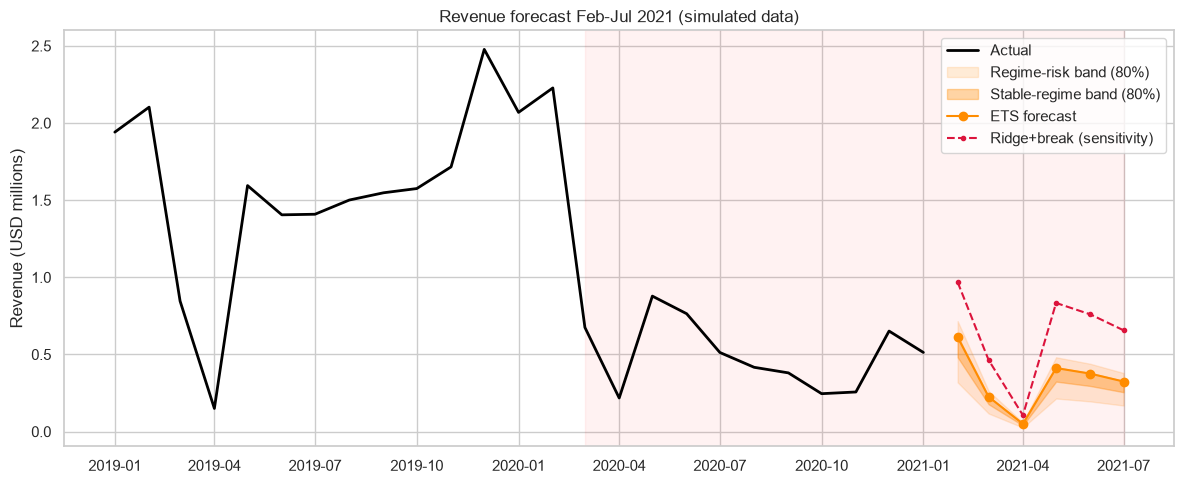

saved


In [14]:
fig, ax = plt.subplots(figsize=(12, 5))
hist = y["2019-01-01":]
ax.plot(hist.index, hist / 1e6, color="black", linewidth=2, label="Actual")
ax.fill_between(fc.index, fc["wide_lo"] / 1e6, fc["wide_hi"] / 1e6, color="darkorange", alpha=0.15,
                label="Regime-risk band (80%)")
ax.fill_between(fc.index, fc["stable_lo"] / 1e6, fc["stable_hi"] / 1e6, color="darkorange", alpha=0.35,
                label="Stable-regime band (80%)")
ax.plot(fc.index, fc["forecast"] / 1e6, color="darkorange", marker="o", label="ETS forecast")
ax.plot(fc.index, fc["ridge_break"] / 1e6, color="crimson", linestyle="--", marker="o", markersize=3,
        label="Ridge+break (sensitivity)")
ax.axvspan(pd.Timestamp("2020-03-01"), fc.index[-1], color="red", alpha=0.05)
ax.set_title("Revenue forecast Feb-Jul 2021 (simulated data)")
ax.set_ylabel("Revenue (USD millions)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/final_forecast.png", dpi=150)
plt.show()

fc.round(0).to_csv("../reports/forecast_feb_jul_2021.csv", index_label="month")
print("saved")